# Week 6: Integrative Capstone Project

## Customer Subscription Prediction and Customer Segmentation Using Data Science

### YUVA Virtual Data Science with Python Internship

This capstone project integrates the major concepts learned throughout the internship, including data acquisition, data cleaning, exploratory data analysis, feature engineering, unsupervised learning, supervised learning, model evaluation, and interpretation.

The project uses the UCI Bank Marketing dataset to analyze customer characteristics, identify meaningful customer segments, and predict whether a customer is likely to subscribe to a bank term deposit.

Two complementary approaches are implemented:

1. **K-Means Clustering** for customer segmentation.
2. **Logistic Regression and Random Forest** for subscription prediction.

The final objective is to combine descriptive and predictive insights to develop practical recommendations for improving customer targeting and marketing decisions.

## 1. Problem Statement

Banks conduct marketing campaigns to encourage customers to subscribe to term deposit products. However, contacting every customer with the same strategy may not be efficient.

The objective of this project is to analyze customer and campaign information and develop a complete data science pipeline that can:

- Understand the characteristics of bank customers.
- Identify important patterns and relationships in the dataset.
- Segment customers into meaningful groups using clustering.
- Predict whether a customer is likely to subscribe to a term deposit.
- Compare different supervised learning models.
- Evaluate model performance using appropriate metrics.
- Generate actionable insights and recommendations from the analysis.

This project demonstrates how data science can support more targeted and data-driven marketing decisions.

## 2. Project Objectives

The major objectives of the capstone project are:

1. Acquire and inspect a publicly available dataset.
2. Clean and preprocess the data.
3. Perform exploratory data analysis and visualization.
4. Engineer useful features from existing variables.
5. Apply K-Means clustering for customer segmentation.
6. Build supervised learning models for subscription prediction.
7. Validate the models using cross-validation.
8. Evaluate the models using accuracy, precision, recall, F1-score, and ROC-AUC.
9. Analyze important features influencing predictions.
10. Combine clustering and prediction results to derive meaningful insights.
11. Provide recommendations and discuss limitations and future improvements.

## 3. Importing Required Libraries

The project uses Python libraries for data manipulation, visualization, preprocessing, clustering, supervised learning, model evaluation, and dimensionality reduction.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("All required libraries imported successfully.")

The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.
All required libraries imported successfully.


## 4. Data Acquisition

The dataset used in this project is the **Bank Marketing dataset**, a publicly available dataset containing information about customers contacted during bank marketing campaigns.

The dataset contains demographic information, financial attributes, communication details, and campaign-related variables. The target variable `y` indicates whether the customer subscribed to a bank term deposit.

The dataset file is stored locally in the project's `data` directory.

In [2]:
DATA_PATH = "data/bank-full.csv"

df = pd.read_csv(DATA_PATH, sep=";")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (45211, 17)


In [3]:
print("First five records:")
display(df.head())

First five records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
print("Dataset Information")
print("=" * 50)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes)

Dataset Information
Rows: 45211
Columns: 17

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data Types:


age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

In [5]:
print("Statistical Summary")
display(df.describe(include="all").T)

Statistical Summary


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


## 5. Data Quality Assessment

Before applying statistical analysis or machine learning algorithms, the dataset must be checked for common data quality issues.

The following checks are performed:

- Missing values
- Duplicate records
- Data types
- Unique categorical values
- Target class distribution
- Potentially problematic numerical values

This ensures that the subsequent analysis is based on reliable and consistent data.

In [6]:
print("Missing Values")
print("=" * 40)
missing_values = df.isnull().sum()

display(
    missing_values[missing_values > 0]
    .to_frame("Missing Count")
)

if missing_values.sum() == 0:
    print("No missing values found.")

Missing Values


,Missing Count


No missing values found.


In [7]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicates removed.")
    
print("Dataset shape after duplicate handling:", df.shape)

Duplicate rows: 0
Dataset shape after duplicate handling: (45211, 17)


In [8]:
print("Target Variable Distribution")
print("=" * 40)

target_counts = df["y"].value_counts()
target_percent = df["y"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percent.round(2)
})

display(target_summary)

Target Variable Distribution


,Count,Percentage
y,,
no,39922,88.3
yes,5289,11.7


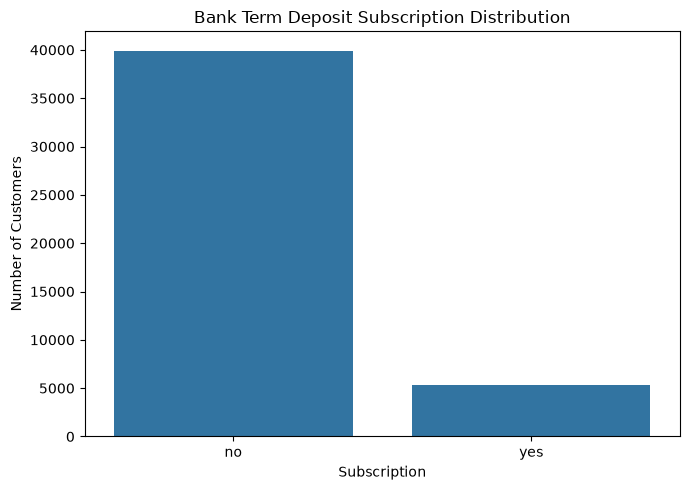

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="y")

plt.title("Bank Term Deposit Subscription Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig("screenshots/02_subscription_distribution.png", dpi=300)
plt.show()

## 6. Feature Engineering

Feature engineering is used to create additional variables that may provide more meaningful information for analysis and modeling.

Two derived features are created:

### Age Group

Customers are grouped into age categories to simplify demographic analysis.

### Balance Category

Customer account balances are grouped into categories based on their values.

### Previous Contact

The `pdays` variable indicates the number of days since a customer was previously contacted. A value of `-1` means the customer was not previously contacted. Therefore, a binary `previous_contact` feature is created.

These engineered features can improve interpretability and help identify meaningful customer patterns.

In [10]:
# Create age groups
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 50, 65, 100],
    labels=["Young", "Adult", "Middle_Aged", "Senior", "Elderly"]
)

# Create balance categories
df["balance_category"] = pd.cut(
    df["balance"],
    bins=[-np.inf, 0, 1000, 5000, np.inf],
    labels=["Negative", "Low", "Medium", "High"]
)

# Create previous contact indicator
df["previous_contact"] = np.where(df["pdays"] == -1, "No", "Yes")

print("Feature engineering completed successfully.")
display(df[[
    "age",
    "age_group",
    "balance",
    "balance_category",
    "pdays",
    "previous_contact"
]].head())

Feature engineering completed successfully.


,age,age_group,balance,balance_category,pdays,previous_contact
0,58,Senior,2143,Medium,-1,No
1,44,Middle_Aged,29,Low,-1,No
2,33,Adult,2,Low,-1,No
3,47,Middle_Aged,1506,Medium,-1,No
4,33,Adult,1,Low,-1,No


## 7. Exploratory Data Analysis

Exploratory Data Analysis is performed to understand customer demographics, financial characteristics, campaign behavior, and their relationship with term deposit subscription.

The analysis focuses on identifying patterns that may help explain why some customers subscribe while others do not.

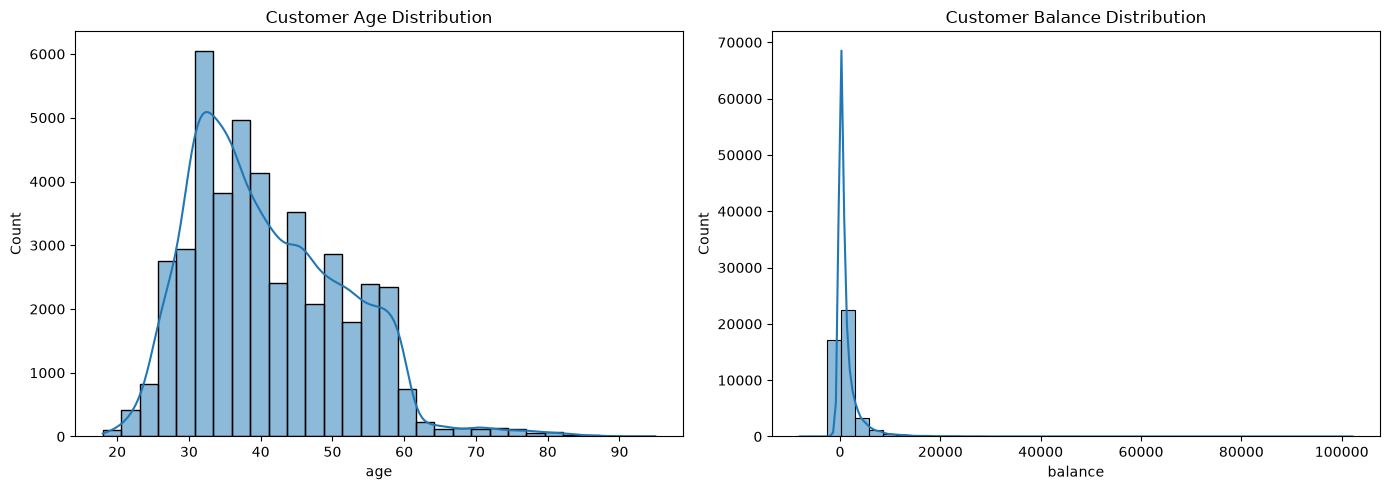

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="age", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Customer Age Distribution")

sns.histplot(data=df, x="balance", bins=40, kde=True, ax=axes[1])
axes[1].set_title("Customer Balance Distribution")

plt.tight_layout()
plt.savefig("screenshots/03_eda_distributions.png", dpi=300)
plt.show()

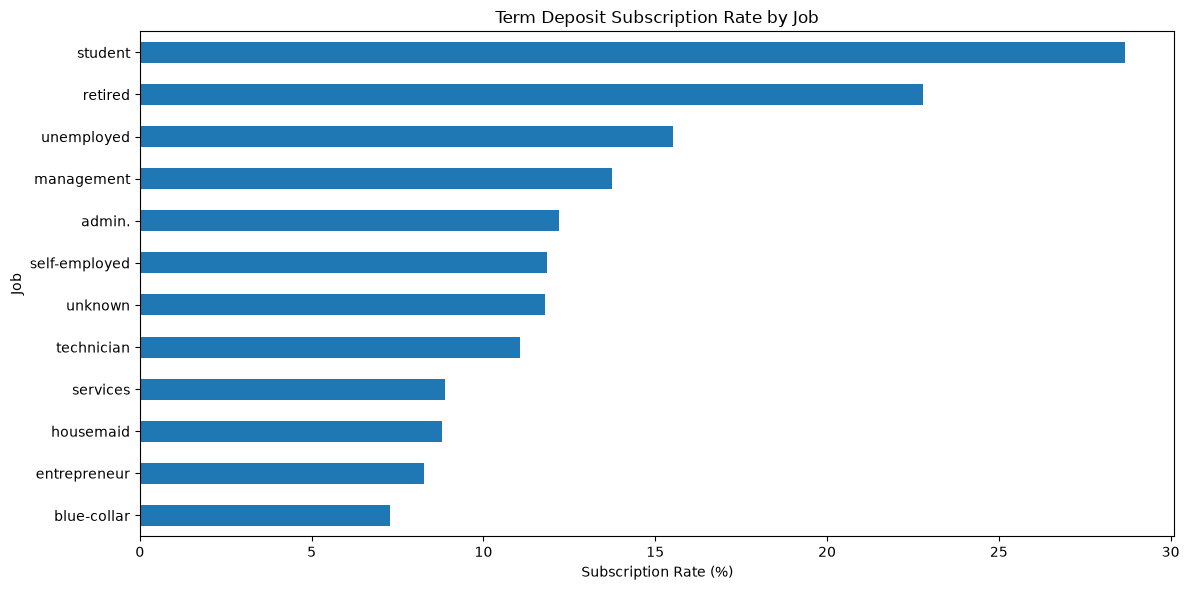

In [12]:
plt.figure(figsize=(12, 6))

subscription_by_job = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

subscription_by_job["yes"].sort_values().plot(kind="barh")

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")
plt.tight_layout()

plt.savefig("screenshots/04_subscription_by_job.png", dpi=300)
plt.show()

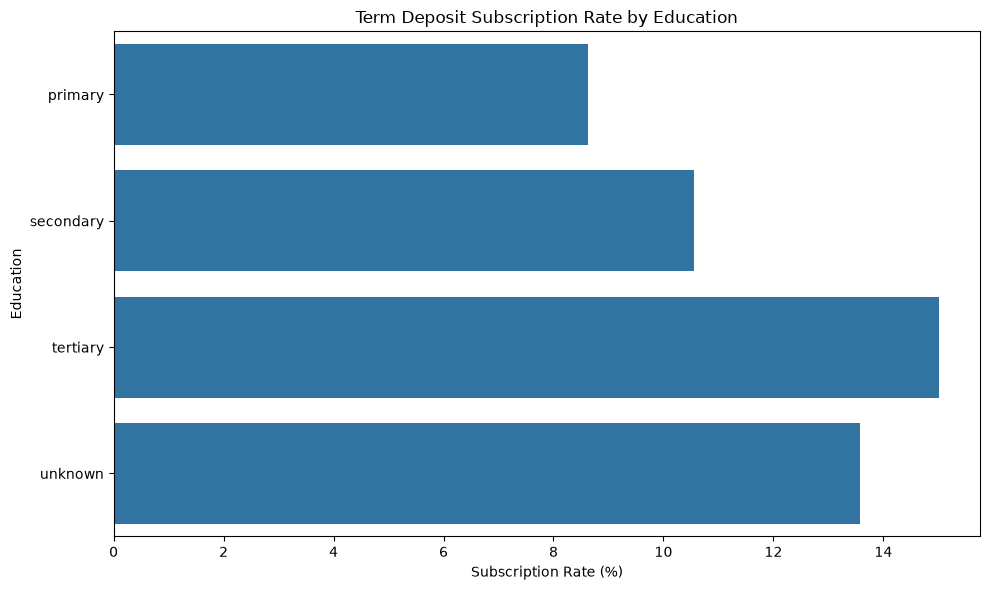

In [13]:
plt.figure(figsize=(10, 6))

education_subscription = pd.crosstab(
    df["education"],
    df["y"],
    normalize="index"
) * 100

sns.barplot(
    x=education_subscription["yes"].values,
    y=education_subscription.index
)

plt.title("Term Deposit Subscription Rate by Education")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Education")
plt.tight_layout()

plt.savefig("screenshots/05_subscription_by_education.png", dpi=300)
plt.show()

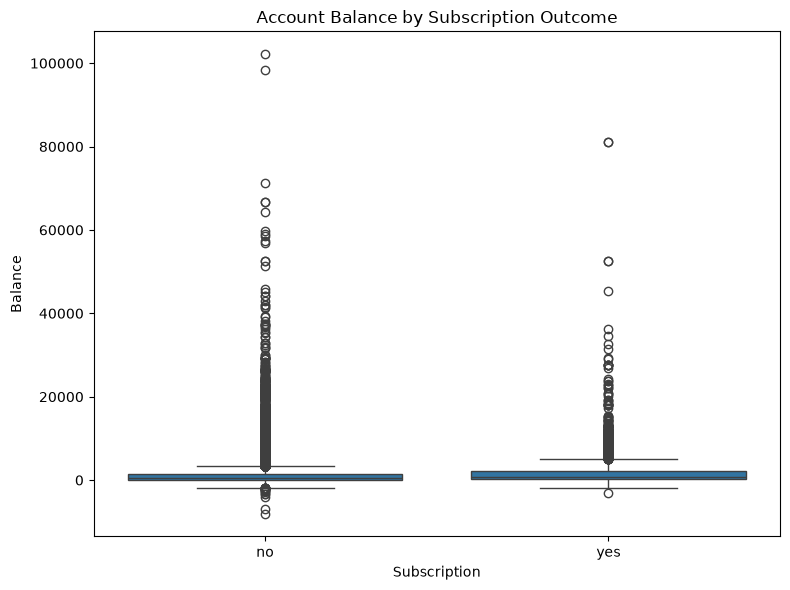

In [14]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="y",
    y="balance"
)

plt.title("Account Balance by Subscription Outcome")
plt.xlabel("Subscription")
plt.ylabel("Balance")

plt.tight_layout()

plt.savefig("screenshots/06_balance_by_subscription.png", dpi=300)
plt.show()

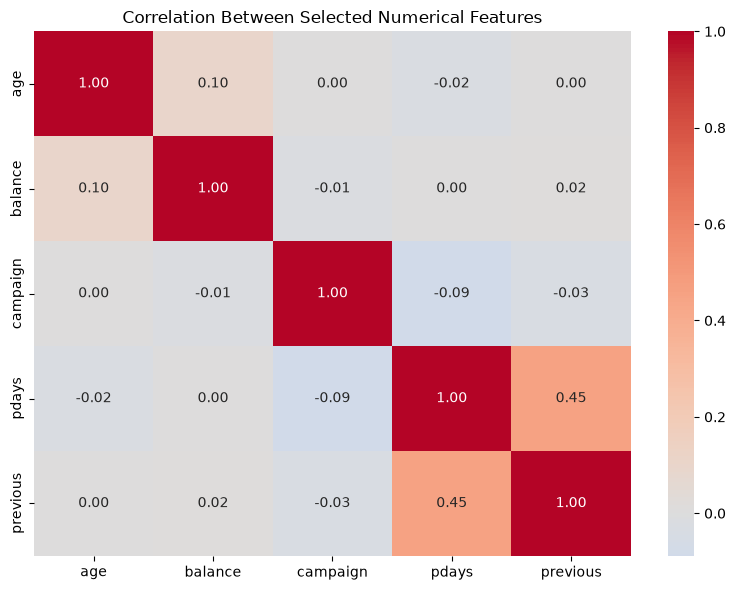

In [15]:
numeric_cols_eda = [
    "age",
    "balance",
    "campaign",
    "pdays",
    "previous"
]

correlation_matrix = df[numeric_cols_eda].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Selected Numerical Features")
plt.tight_layout()

plt.savefig("screenshots/07_correlation_heatmap.png", dpi=300)
plt.show()

## 8. Customer Segmentation Using K-Means Clustering

Customer segmentation is performed to identify groups of customers with similar characteristics.

K-Means clustering is selected because it is a widely used unsupervised learning algorithm that partitions observations into a predefined number of clusters.

The following numerical attributes are used for segmentation:

- Age
- Account balance
- Number of campaign contacts
- Days since previous contact
- Number of previous contacts

The target variable `y` is not used for clustering because clustering should identify groups without using the known subscription outcome.

In [16]:
cluster_features = [
    "age",
    "balance",
    "campaign",
    "pdays",
    "previous"
]

cluster_data = df[cluster_features].copy()

# Replace -1 in pdays with 0 for segmentation
cluster_data["pdays"] = cluster_data["pdays"].replace(-1, 0)

scaler_cluster = StandardScaler()

cluster_scaled = scaler_cluster.fit_transform(cluster_data)

print("Clustering data prepared.")
print("Features used:", cluster_features)
print("Scaled data shape:", cluster_scaled.shape)

Clustering data prepared.
Features used: ['age', 'balance', 'campaign', 'pdays', 'previous']
Scaled data shape: (45211, 5)


### Selecting the Number of Clusters

The Elbow Method and Silhouette Score are used to determine an appropriate number of clusters.

The Elbow Method examines the within-cluster sum of squares, while the Silhouette Score measures how well observations fit within their assigned clusters.

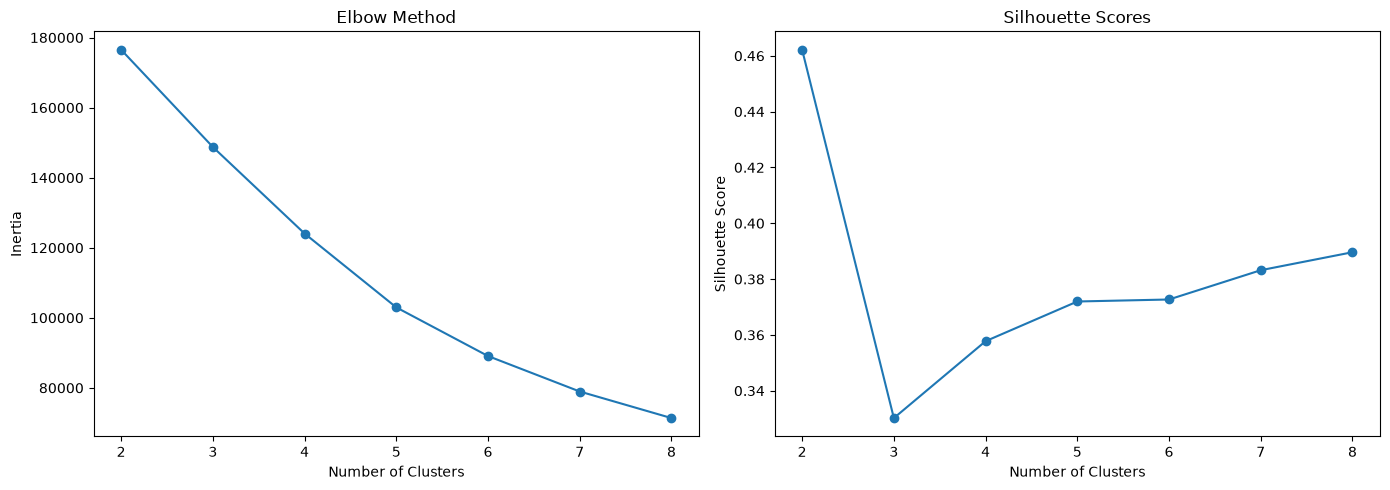

Best K based on Silhouette Score: 2
Best Silhouette Score: 0.4622


In [17]:
inertia_values = []
silhouette_values = []

k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(cluster_scaled)
    
    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(cluster_scaled, labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, inertia_values, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouette_values, marker="o")
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()

plt.savefig("screenshots/08_clustering_selection.png", dpi=300)
plt.show()

best_k = list(k_values)[np.argmax(silhouette_values)]

print("Best K based on Silhouette Score:", best_k)
print(
    "Best Silhouette Score:",
    round(max(silhouette_values), 4)
)

In [18]:
kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans_model.fit_predict(cluster_scaled)

print("K-Means clustering completed.")
print("\nCluster Sizes:")
display(df["cluster"].value_counts().sort_index())

K-Means clustering completed.

Cluster Sizes:


cluster
0    38226
1     6985
Name: count, dtype: int64

Variance explained by PCA components: 29.42 % and 21.97 %


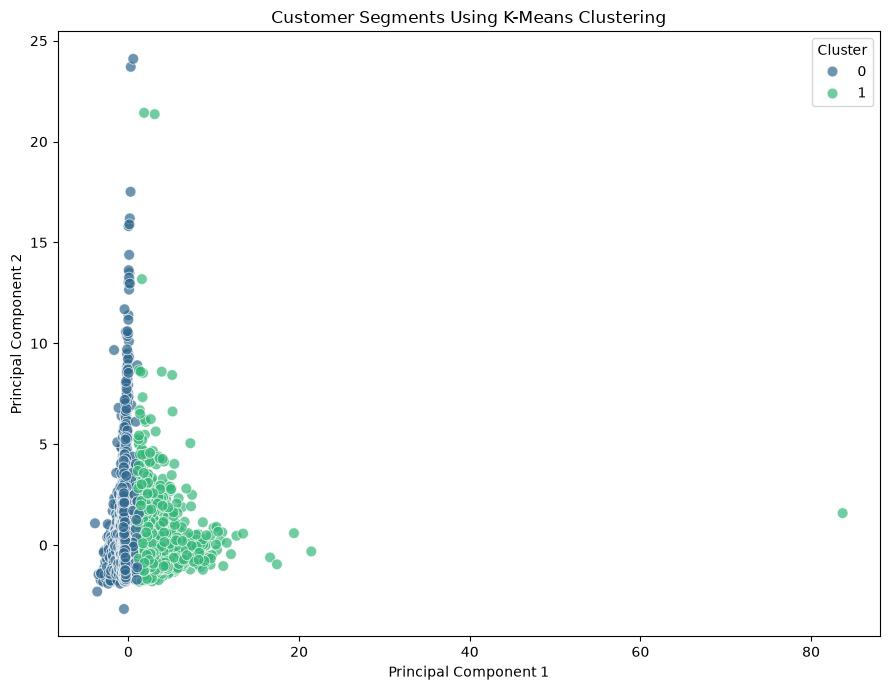

In [19]:
pca = PCA(n_components=2, random_state=42)

cluster_pca = pca.fit_transform(cluster_scaled)

df["PCA1"] = cluster_pca[:, 0]
df["PCA2"] = cluster_pca[:, 1]

explained_variance = pca.explained_variance_ratio_

print(
    "Variance explained by PCA components:",
    round(explained_variance[0] * 100, 2), "%",
    "and",
    round(explained_variance[1] * 100, 2), "%"
)

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=df,
    x="PCA1",
    y="PCA2",
    hue="cluster",
    palette="viridis",
    s=60,
    alpha=0.7
)

plt.title("Customer Segments Using K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")

plt.tight_layout()

plt.savefig("screenshots/09_cluster_visualization.png", dpi=300)
plt.show()

In [20]:
cluster_profile = df.groupby("cluster")[
    ["age", "balance", "campaign", "pdays", "previous"]
].mean().round(2)

cluster_profile["customer_count"] = df["cluster"].value_counts().sort_index()

print("Customer Cluster Profile")
display(cluster_profile)

Customer Cluster Profile


,age,balance,campaign,pdays,previous,customer_count
cluster,,,,,,
0,40.96,1330.73,2.89,1.81,0.06,38226
1,40.83,1534.87,2.10,250.30,3.45,6985


Subscription Rate by Customer Cluster


y,no,yes
cluster,,
0,90.02,9.98
1,78.90,21.10


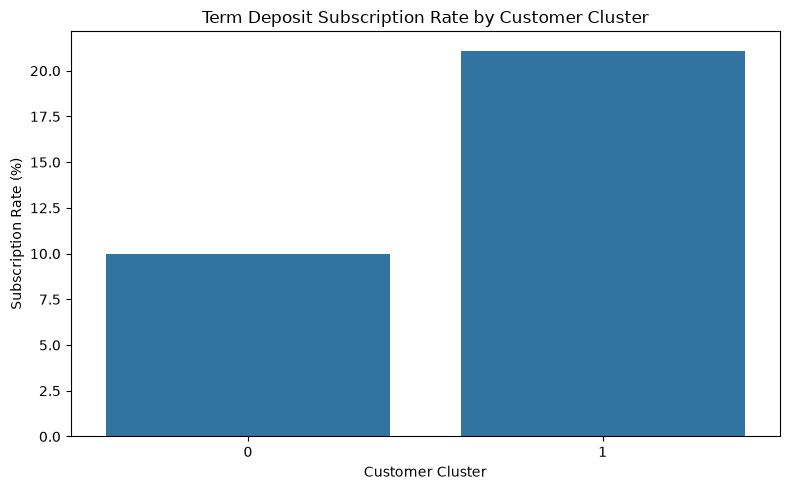

In [21]:
cluster_subscription = pd.crosstab(
    df["cluster"],
    df["y"],
    normalize="index"
) * 100

cluster_subscription = cluster_subscription.round(2)

print("Subscription Rate by Customer Cluster")
display(cluster_subscription)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_subscription.index,
    y=cluster_subscription["yes"].values
)

plt.title("Term Deposit Subscription Rate by Customer Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Subscription Rate (%)")

plt.tight_layout()

plt.savefig("screenshots/10_cluster_subscription.png", dpi=300)
plt.show()

## 9. Term Deposit Subscription Prediction

A supervised learning problem is defined to predict whether a customer will subscribe to a bank term deposit.

The target variable is:

`y`

where:

- `yes` = customer subscribed
- `no` = customer did not subscribe

Two classification algorithms are implemented:

1. Logistic Regression
2. Random Forest

The variable `duration` is excluded from the predictive features because it represents the duration of the current contact and may introduce data leakage when making predictions before or at the beginning of a marketing interaction.

In [22]:
model_df = df.copy()

# Remove columns not required for supervised prediction
drop_columns = [
    "y",
    "duration",
    "cluster",
    "PCA1",
    "PCA2"
]

X = model_df.drop(columns=drop_columns)

y = model_df["y"].map({
    "no": 0,
    "yes": 1
})

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
display(y.value_counts())

Feature matrix shape: (45211, 18)
Target shape: (45211,)

Target distribution:


y
0    39922
1     5289
Name: count, dtype: int64

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 36168
Testing samples: 9043


### Preprocessing Pipeline

Numerical features are processed using median imputation and standardization.

Categorical features are processed using most-frequent-value imputation and one-hot encoding.

A `ColumnTransformer` is used so that the preprocessing steps are applied consistently to both training and testing data.

In [24]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 6
Categorical features: 12


In [25]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

logistic_pipeline.fit(X_train, y_train)
random_forest_pipeline.fit(X_train, y_train)

print("Both supervised learning models trained successfully.")

Both supervised learning models trained successfully.


## 10. Model Evaluation

The trained models are evaluated using multiple classification metrics.

The following metrics are used:

- Accuracy: overall percentage of correct predictions.
- Precision: proportion of predicted positive cases that are actually positive.
- Recall: proportion of actual positive cases correctly identified.
- F1-score: harmonic mean of precision and recall.
- ROC-AUC: ability of the model to distinguish between the two classes.

Because the dataset contains an imbalance between subscribed and non-subscribed customers, accuracy alone is not sufficient for evaluating the models.

In [26]:
models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.3f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,76.71%,28.20%,64.08%,39.17%,0.778
1,Random Forest,82.03%,34.91%,62.00%,44.67%,0.798


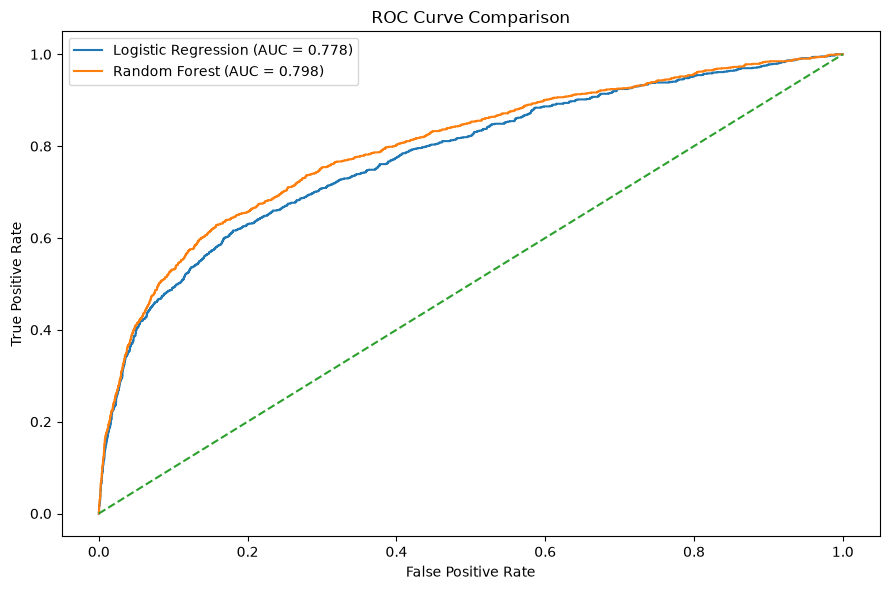

In [27]:
plt.figure(figsize=(9, 6))

for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_score = roc_auc_score(y_test, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.tight_layout()

plt.savefig("screenshots/12_roc_curve.png", dpi=300)
plt.show()

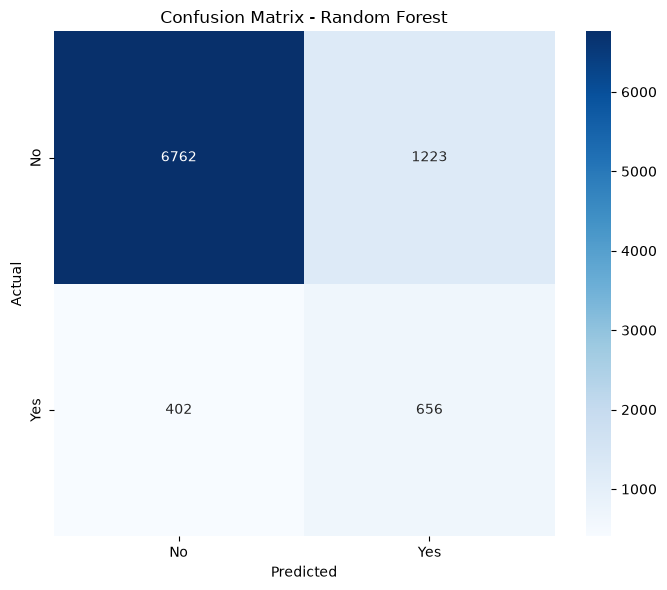

Best model based on ROC-AUC: Random Forest


In [28]:
best_model_name = results_df.loc[
    results_df["ROC-AUC"].idxmax(),
    "Model"
]

best_model = models[best_model_name]

best_predictions = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig("screenshots/13_confusion_matrix.png", dpi=300)
plt.show()

print("Best model based on ROC-AUC:", best_model_name)

## 11. Feature Importance

Feature importance is analyzed to understand which variables contribute most strongly to the Random Forest model's predictions.

Understanding influential features helps convert the machine learning model into interpretable insights and can support better business decision-making.

,Feature,Importance
48,categorical__poutcome_success,0.092615
33,categorical__contact_unknown,0.072724
0,numeric__age,0.063336
4,numeric__pdays,0.058170
1,numeric__balance,0.056721
2,numeric__day,0.049858
28,categorical__housing_yes,0.049223
31,categorical__contact_cellular,0.042410
27,categorical__housing_no,0.040107
5,numeric__previous,0.032710


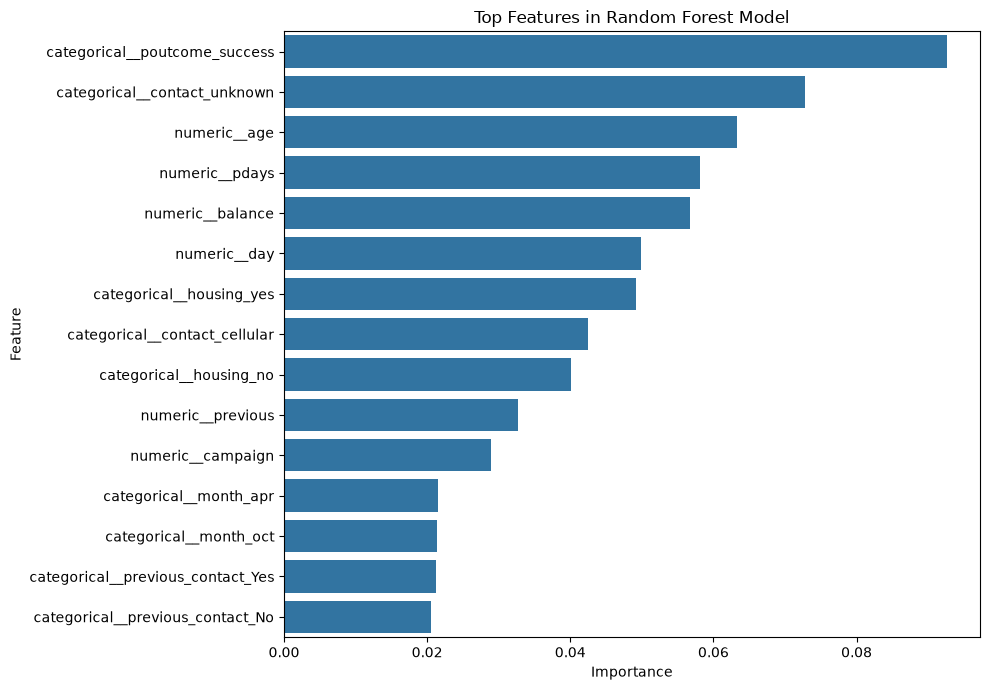

In [29]:
rf_model = random_forest_pipeline.named_steps["classifier"]
rf_preprocessor = random_forest_pipeline.named_steps["preprocessor"]

feature_names = rf_preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).head(15)

display(feature_importance)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Top Features in Random Forest Model")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig("screenshots/14_feature_importance.png", dpi=300)
plt.show()

## 12. Cross-Validation

To obtain a more reliable estimate of model performance, Stratified 5-Fold Cross-Validation is performed.

Stratification ensures that each fold maintains a similar distribution of the target classes.

The models are evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

In [30]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.3f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,76.28%,27.52%,62.85%,38.28%,0.771
1,Random Forest,81.60%,33.91%,60.33%,43.41%,0.792


## 13. Integrated Customer Analysis

The clustering and supervised learning results are combined to obtain a broader understanding of customer behavior.

Customer segmentation provides descriptive information about groups of customers, while the predictive models estimate the likelihood of subscription.

By comparing subscription rates across clusters, it is possible to identify customer groups that may deserve different marketing strategies.

In [31]:
integrated_analysis = df.groupby("cluster").agg(
    customer_count=("cluster", "size"),
    average_age=("age", "mean"),
    average_balance=("balance", "mean"),
    average_campaign_contacts=("campaign", "mean"),
    subscription_rate=("y", lambda x: (x == "yes").mean() * 100)
).round(2)

print("Integrated Customer Segment Analysis")
display(integrated_analysis)

Integrated Customer Segment Analysis


,customer_count,average_age,average_balance,average_campaign_contacts,subscription_rate
cluster,,,,,
0,38226,40.96,1330.73,2.89,9.98
1,6985,40.83,1534.87,2.10,21.10


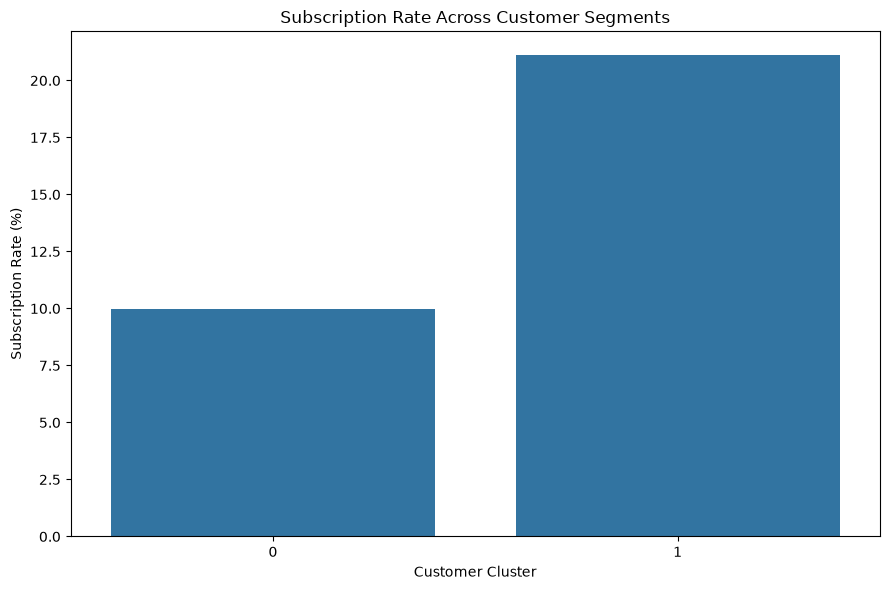

In [32]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=integrated_analysis.reset_index(),
    x="cluster",
    y="subscription_rate"
)

plt.title("Subscription Rate Across Customer Segments")
plt.xlabel("Customer Cluster")
plt.ylabel("Subscription Rate (%)")

plt.tight_layout()

plt.savefig("screenshots/15_integrated_analysis.png", dpi=300)
plt.show()

## 14. Key Insights

The main insights obtained from the complete analysis are summarized below.

### Customer Characteristics

The exploratory analysis provides an understanding of customer demographics, financial characteristics, and campaign behavior.

### Customer Segmentation

K-Means clustering identifies distinct customer groups based on demographic, financial, and campaign-related characteristics. The cluster profiles help describe how customer groups differ.

### Subscription Prediction

The supervised learning models provide a predictive mechanism for identifying customers who are more likely to subscribe to a term deposit.

### Important Predictors

Feature importance analysis identifies the variables that contribute most strongly to the Random Forest model's predictions.

### Integrated Findings

Combining customer segmentation with subscription prediction provides a more complete view of customer behavior than using either approach independently.

## 15. Recommendations

Based on the findings from exploratory analysis, customer segmentation, and predictive modeling, the following recommendations can be considered:

1. Use predictive models to prioritize customers who have a higher estimated probability of subscribing.
2. Develop different marketing strategies for different customer segments rather than using a single strategy for all customers.
3. Give greater attention to customer characteristics identified as important by the predictive model.
4. Use historical campaign information to improve future customer targeting.
5. Monitor model performance regularly because customer behavior and campaign effectiveness may change over time.
6. Combine automated predictions with business expertise rather than relying exclusively on machine learning predictions.

## 16. Challenges and Limitations

Several challenges were considered during the project.

### Class Imbalance

The number of customers who did not subscribe is considerably larger than the number who subscribed. Therefore, accuracy alone is not sufficient for judging model performance.

### Data Leakage

The `duration` feature was excluded from predictive modeling because it represents information associated with the ongoing customer interaction and would not be available when making an initial prediction.

### Clustering Feature Selection

Selecting appropriate variables for clustering is important because irrelevant or highly skewed features can affect the resulting customer segments.

### Model Interpretability

Although Random Forest can provide feature importance, machine learning predictions should still be interpreted carefully.

### Dataset Limitations

The dataset represents a particular banking marketing campaign and may not perfectly represent customer behavior in other banks, regions, or time periods.

## 17. Future Improvements

The project can be extended in several ways:

- Test additional classification algorithms such as Gradient Boosting or XGBoost.
- Apply hyperparameter optimization.
- Experiment with alternative clustering algorithms such as Hierarchical Clustering or DBSCAN.
- Address class imbalance using techniques such as SMOTE.
- Perform more extensive feature engineering.
- Evaluate the models on newer campaign data.
- Develop a deployment interface for business users.
- Monitor model performance over time after deployment.

## 18. Final Project Validation

The final validation checks whether the major components of the capstone project were successfully completed.

The validation includes:

- Dataset availability
- Dataset dimensions
- Missing-value status
- Duplicate handling
- Number of clusters
- Number of supervised models
- Test dataset size
- Best-performing model
- Final evaluation metrics

In [33]:
print("=" * 60)
print("FINAL CAPSTONE PROJECT VALIDATION")
print("=" * 60)

print("Final dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())

print("\nClustering")
print("Number of clusters:", best_k)
print("Best silhouette score:", round(max(silhouette_values), 4))

print("\nSupervised Learning")
print("Models trained:", len(models))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nBest Model")
print("Model:", best_model_name)

best_result = results_df[
    results_df["Model"] == best_model_name
].iloc[0]

print("Accuracy:", round(best_result["Accuracy"], 4))
print("Precision:", round(best_result["Precision"], 4))
print("Recall:", round(best_result["Recall"], 4))
print("F1 Score:", round(best_result["F1 Score"], 4))
print("ROC-AUC:", round(best_result["ROC-AUC"], 4))

print("\nValidation completed successfully.")

FINAL CAPSTONE PROJECT VALIDATION
Final dataset shape: (45211, 23)
Missing values: 0
Remaining duplicate rows: 0

Clustering
Number of clusters: 2
Best silhouette score: 0.4622

Supervised Learning
Models trained: 2
Training samples: 36168
Testing samples: 9043

Best Model
Model: Random Forest
Accuracy: 0.8203
Precision: 0.3491
Recall: 0.62
F1 Score: 0.4467
ROC-AUC: 0.7978

Validation completed successfully.


In [34]:
os.makedirs("output", exist_ok=True)

# Save model comparison
results_df.to_csv(
    "output/model_comparison.csv",
    index=False
)

# Save cross-validation results
cv_results_df.to_csv(
    "output/cross_validation_results.csv",
    index=False
)

# Save cluster profiles
cluster_profile.to_csv(
    "output/cluster_profile.csv"
)

# Save integrated analysis
integrated_analysis.to_csv(
    "output/integrated_customer_analysis.csv"
)

# Save final dataset
df.to_csv(
    "output/capstone_analysis_dataset.csv",
    index=False
)

print("All output files saved successfully.")

All output files saved successfully.


## 19. Conclusion

This integrative capstone project demonstrated a complete data science workflow using Python, beginning with data acquisition and preprocessing and continuing through exploratory analysis, customer segmentation, predictive modeling, evaluation, and interpretation.

K-Means clustering was used to identify meaningful customer segments based on demographic, financial, and campaign-related characteristics. Logistic Regression and Random Forest were implemented to predict term deposit subscription, with multiple evaluation metrics and cross-validation used to assess their performance.

The combination of descriptive clustering and predictive modeling provides a broader understanding of customer behavior. The findings can support more targeted marketing strategies by helping organizations identify customer groups and prioritize potential customers.

The project also highlighted important practical considerations including class imbalance, feature engineering, data leakage, model selection, and model limitations.

Overall, the capstone integrates the major data science techniques learned during the internship and demonstrates their application in a realistic business problem.